In [46]:
import numpy as np
import matplotlib.pyplot as plt

# Parameters

In [47]:
array_length = 128 #elements
pitch = 0.110e-3 #m
frequency = 1.5e+7 #hz
c = 1500 #m/s
sampling_rate = 16 * frequency  #hz

object_depth = 3e-3 #m
object_position = 7e-3 #m

object2_depth = 4e-3 #m
object2_position = 8e-3 #m

object3_depth = 3.1e-3 #m
object3_position = 7.5e-3 #m

total_depth = 1e-2 #m

step_size = total_depth / c #s
samples = int(sampling_rate * step_size)

pos = np.linspace(start=0, stop=array_length, num=array_length, dtype=int) #position sampling
time = np.linspace(start=0, stop=step_size, num=samples) #time sampling

print("Samples: ", samples)
print("Step size: ", step_size, "µs")

Samples:  1600
Step size:  6.666666666666667e-06 µs


# Objects

In [48]:
class Objects:
    def __init__(self, depth, position):
        self.depth = depth
        self.position = position
        self.delays = np.zeros(array_length)
        self.rf_matrix = np.zeros((samples, array_length))

In [49]:
objects = [Objects(object_depth, object_position)]#, Objects(object2_depth, object2_position), Objects(object3_depth, object3_position)]
obj_nbr = len(objects)

# Signals

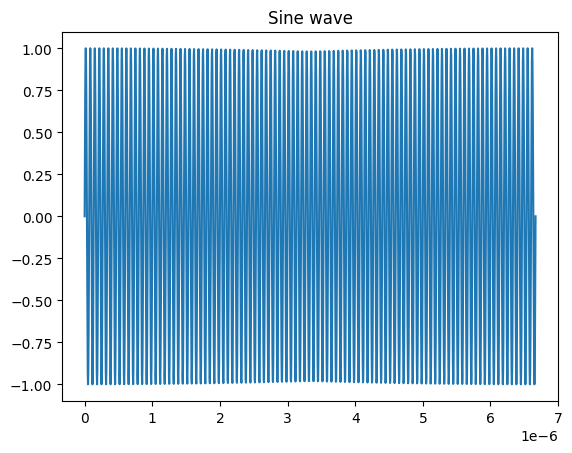

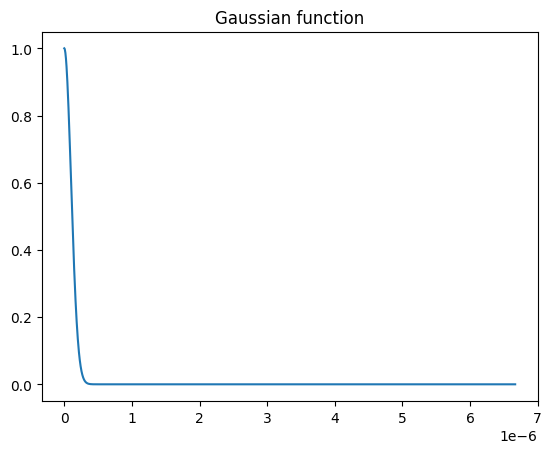

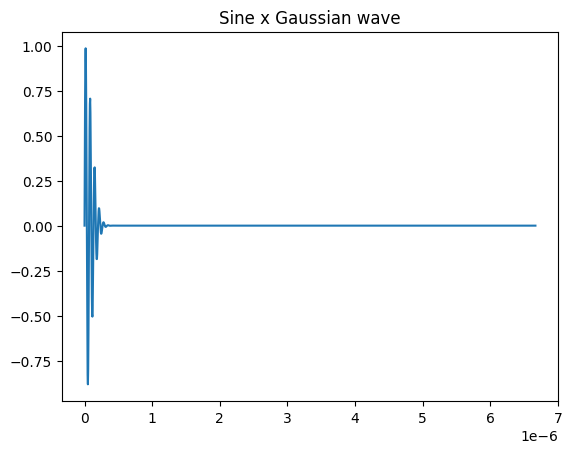

In [50]:
gaussian_std = 0.0000001

def sine_wave(frequency, timestep):
    return np.sin(2*np.pi*frequency*timestep )#+ np.pi/2)

def gaussian_function(timestep, std):
    return np.exp(-timestep**2 / (2 * std**2))

def generate_wave(frequency, timestep, std):
    return sine_wave(frequency, timestep) * gaussian_function(timestep, std)

wave = sine_wave(frequency, time)
plt.plot(time, wave)
plt.title("Sine wave")
plt.show()

wave = gaussian_function(time, gaussian_std)
plt.plot(time, wave)
plt.title("Gaussian function")
plt.show()

wave = generate_wave(frequency, time, gaussian_std)
plt.plot(time, wave)
plt.title("Sine x Gaussian wave")
plt.show()

# NSI (null substraction imaging)

In [55]:
def generate_apodization(array_length, index, offset=0, mirror=False):
    if index >= 1 and index < array_length / 2:
        if mirror:
            return -1 + offset
        else:
            return 1 + offset
    elif index>=array_length/2 and index < array_length:
        if mirror:
            return 1 + offset
        else:
            return -1 + offset

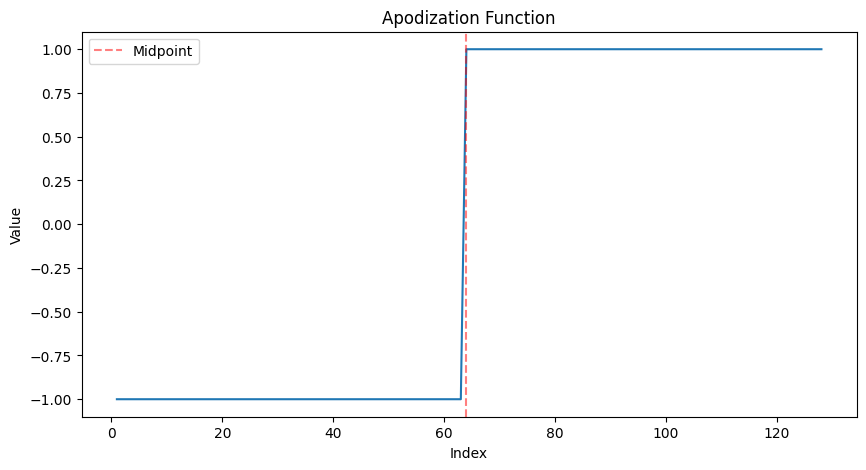

In [59]:
import numpy as np
import matplotlib.pyplot as plt

# Apply the apodization function to each element
y = np.array([generate_apodization(array_length, i, offset=0, mirror=True) for i in range(array_length)])

plt.figure(figsize=(10, 5))
plt.plot(pos, y)
plt.title('Apodization Function')
plt.xlabel('Index')
plt.ylabel('Value')
plt.axvline(x=array_length/2, color='r', linestyle='--', alpha=0.5, label='Midpoint')
plt.legend()
plt.show()